### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Week 8: Long Lookback and Intraday Candlestick Features for Hit-Count Events

This notebook first tests whether more daily history improves next-day `hit_count` peak and spike detection. It then compares the best daily model with a model that receives causal hourly-derived candlestick features from completed prior days.

## 1. Experimental protocol

- Target: six daily XCache variables; `hit_count` is the primary evaluation variable.
- Forecast horizon: one day.
- Period: post-change-point regime, 2022-07-01 to 2024-03-31, with chronological 70% / 15% / 15% train / validation / test splits.
- Model: five-block, 64-channel hard Structured TCN.
- Long-lookback scan: 14, 28, 56, and 112 days.
- Model selection: lowest validation `hit_count` RMSE. The test set is held out until selection is complete.
- Events: peak = level above the training 90th percentile; spike = one-day increase above the training 90th percentile.

In [1]:
from pathlib import Path
import copy
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_VARIABLE = 'hit_count'
PRIMARY_INDEX = FEATURE_NAMES.index(PRIMARY_VARIABLE)
CHANNELS = (64, 64, 64, 64, 64)
KERNEL_SIZE, DROPOUT = 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
PEAK_QUANTILE, SPIKE_QUANTILE = 0.90, 0.90
LONG_LOOKBACKS = [14, 28, 56, 112]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('xcache-ts-df')]
daily_path = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
hourly_path = next((directory / 'socal-2006-2403-hourly-ml' for directory in data_dirs if (directory / 'socal-2006-2403-hourly-ml').is_file()), None)
if daily_path is None or hourly_path is None:
    raise FileNotFoundError('Cannot find the SoCal daily and hourly data files.')

daily_df = pd.read_pickle(daily_path).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
hourly_df = pd.read_pickle(hourly_path).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
daily_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
hourly_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert daily_df.index.equals(pd.date_range('2020-05-31', '2024-03-31', freq='D'))
np.testing.assert_allclose(daily_df['access_count'], daily_df['hit_count'] + daily_df['miss_count'])
np.testing.assert_allclose(daily_df['access_size'], daily_df['hit_size'] + daily_df['miss_size'])
raw_values = daily_df.to_numpy(dtype=np.float32)
date_to_position = pd.Series(np.arange(len(daily_df)), index=daily_df.index)

def chronological_split(start, end):
    dates = pd.date_range(start, end, freq='D')
    n_train, n_validation = int(.70 * len(dates)), int(.15 * len(dates))
    return {'train_start': dates[0], 'train_end': dates[n_train - 1],
            'validation_start': dates[n_train], 'validation_end': dates[n_train + n_validation - 1],
            'test_start': dates[n_train + n_validation], 'test_end': dates[-1]}

split = chronological_split('2022-07-01', '2024-03-31')
display(pd.DataFrame([{'subset': part.title(), 'first target': split[f'{part}_start'].date(), 'last target': split[f'{part}_end'].date(), 'days': len(pd.date_range(split[f'{part}_start'], split[f'{part}_end']))} for part in ['train', 'validation', 'test']]))
print('Device:', device)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

,subset,first target,last target,days
0,Train,2022-07-01,2023-09-21,448
1,Validation,2023-09-22,2023-12-26,96
2,Test,2023-12-27,2024-03-31,96


Device: cpu


## 2. Build daily intraday summary features from all six hourly variables

For each completed day and each XCache variable, retain hourly high, low, mean, and high-low range. This gives 4 summaries x 6 variables = 24 additional input features. The number of hourly observations is used only to reject incomplete days; it is not an input feature. For a target day `t`, the input sequence ends at `t-1`; therefore, no hourly observation from the target day is used.

In [11]:
def build_all_variable_candles(hourly_frame, daily_index, variables):
    day_key = hourly_frame.index.normalize()
    hourly_observations = hourly_frame.groupby(day_key).size().reindex(daily_index)
    feature_data = {}
    for variable in variables:
        grouped = hourly_frame[variable].groupby(day_key)
        high = grouped.max().reindex(daily_index)
        low = grouped.min().reindex(daily_index)
        feature_data[f'hourly_{variable}_high'] = high
        feature_data[f'hourly_{variable}_low'] = low
        feature_data[f'hourly_{variable}_mean'] = grouped.mean().reindex(daily_index)
        feature_data[f'hourly_{variable}_range'] = high - low
    candles = pd.DataFrame(feature_data, index=daily_index)
    # hourly_observations is a quality-control field, not a model feature.
    candles.loc[hourly_observations != 24, :] = np.nan
    return candles

candle_df = build_all_variable_candles(hourly_df, daily_df.index, FEATURE_NAMES)
CANDLE_NAMES = list(candle_df.columns)
display(candle_df.head())
print('Candlestick features:', len(CANDLE_NAMES))
print('Days with incomplete hourly coverage:', int(candle_df.isna().any(axis=1).sum()))

,hourly_access_count_high,hourly_access_count_low,hourly_access_count_mean,hourly_access_count_range,hourly_access_size_high,hourly_access_size_low,hourly_access_size_mean,hourly_access_size_range,hourly_hit_count_high,hourly_hit_count_low,...,hourly_hit_size_mean,hourly_hit_size_range,hourly_miss_count_high,hourly_miss_count_low,hourly_miss_count_mean,hourly_miss_count_range,hourly_miss_size_high,hourly_miss_size_low,hourly_miss_size_mean,hourly_miss_size_range
data_start_time_datetime,,,,,,,,,,,,,,,,,,,,,
2020-05-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-06-01,2390.0,1004.0,1557.958333,1386.0,1.549375,0.585441,0.987504,0.963934,1758.0,641.0,...,0.586409,0.672561,1089.0,108.0,603.416667,981.0,0.723777,0.065170,0.401095,0.658607
2020-06-02,6212.0,1178.0,2545.333333,5034.0,2.574115,0.584889,1.449491,1.989227,2723.0,663.0,...,0.497345,0.808895,3489.0,449.0,1481.208333,3040.0,1.608433,0.290163,0.952147,1.318270
2020-06-03,2199.0,898.0,1498.041667,1301.0,2.120105,0.462962,1.101614,1.657143,1432.0,651.0,...,0.752420,1.294151,993.0,213.0,511.000000,780.0,0.690754,0.121069,0.349194,0.569684
2020-06-04,2819.0,1403.0,1842.416667,1416.0,3.006288,1.109618,1.670416,1.896670,2102.0,1023.0,...,1.112028,1.560742,999.0,316.0,525.750000,683.0,1.562904,0.290978,0.558388,1.271925


Candlestick features: 24
Days with incomplete hourly coverage: 2


## 3. Define the five-block Structured TCN and evaluation functions

In [12]:
class Chomp1d(nn.Module):
    def __init__(self, size):
        super().__init__(); self.size = size
    def forward(self, x):
        return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__()
        padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT),
        )
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x):
        return torch.relu(self.net(x) + self.residual(x))

class StructuredTCN(nn.Module):
    def __init__(self, input_channels):
        super().__init__()
        blocks, in_channels = [], input_channels
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level))
            in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1], 4)
    def forward(self, x):
        output = self.output(self.tcn(x)[:, :, -1])
        return torch.cat([output[:, :2], torch.sigmoid(output[:, 2:])], dim=1)

def structured_loss(prediction, target):
    return nn.functional.mse_loss(prediction[:, :2], target[:, :2]) + 5 * nn.functional.mse_loss(prediction[:, 2:], target[:, 2:])

def make_loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1), dtype=torch.float32), torch.tensor(y, dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def precision_recall(observed, forecast):
    true_positive = int(np.sum(observed & forecast))
    return true_positive / max(int(forecast.sum()), 1), true_positive / max(int(observed.sum()), 1)

def top_k_recall(observed, score):
    k = int(observed.sum())
    if k == 0: return np.nan
    selected = np.zeros(len(score), dtype=bool)
    selected[np.argsort(score)[-k:]] = True
    return float(np.sum(observed & selected) / k)

## 4. Train and evaluate one configuration

The target labels remain log-access and hit ratios, so the decoder preserves `access = hit + miss`. Input channels are either the six daily variables alone or the six daily variables plus seven hourly candlestick features.

In [13]:
def fit_and_evaluate(lookback, use_candles=False, seed=SEED):
    train_raw = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()
    validation_positions = date_to_position.loc[split['validation_start']:split['validation_end']].to_numpy()
    test_positions = date_to_position.loc[split['test_start']:split['test_end']].to_numpy()
    # Keep every input window entirely inside the post-change-point regime.
    train_positions = train_raw[train_raw >= train_raw[0] + lookback]
    validation_positions = validation_positions[validation_positions >= lookback]
    test_positions = test_positions[test_positions >= lookback]

    base_inputs = np.log1p(raw_values).astype(np.float32)
    if use_candles:
        candle_values = candle_df.to_numpy(dtype=np.float32)
        all_inputs = np.column_stack([base_inputs, candle_values])
    else:
        all_inputs = base_inputs
    valid_train_rows = train_raw[~np.isnan(all_inputs[train_raw]).any(axis=1)]
    input_scaler = StandardScaler().fit(all_inputs[valid_train_rows])
    inputs = input_scaler.transform(all_inputs).astype(np.float32)

    count_ratio = np.divide(raw_values[:, 2], raw_values[:, 0], out=np.zeros(len(daily_df), dtype=np.float32), where=raw_values[:, 0] > 0)
    size_ratio = np.divide(raw_values[:, 3], raw_values[:, 1], out=np.zeros(len(daily_df), dtype=np.float32), where=raw_values[:, 1] > 0)
    log_access = np.column_stack([np.log1p(raw_values[:, 0]), np.log1p(raw_values[:, 1])]).astype(np.float32)
    access_scaler = StandardScaler().fit(log_access[train_raw])
    labels = np.column_stack([access_scaler.transform(log_access), count_ratio, size_ratio]).astype(np.float32)

    def sequences(positions):
        return np.asarray([inputs[position - lookback:position] for position in positions], dtype=np.float32)
    x_train, y_train = sequences(train_positions), labels[train_positions]
    x_validation, y_validation = sequences(validation_positions), labels[validation_positions]
    x_test = sequences(test_positions)
    if np.isnan(x_train).any() or np.isnan(x_validation).any() or np.isnan(x_test).any():
        raise ValueError('An input window contains incomplete hourly data. Increase the initial buffer or inspect hourly coverage.')

    def decode(model, features):
        model.eval(); rows = []
        with torch.no_grad():
            for start in range(0, len(features), BATCH_SIZE):
                batch = torch.tensor(features[start:start + BATCH_SIZE].transpose(0, 2, 1), dtype=torch.float32, device=device)
                rows.extend(model(batch).cpu().tolist())
        output = np.asarray(rows, dtype=np.float64)
        access = np.maximum(np.expm1(access_scaler.inverse_transform(output[:, :2])), 0)
        ratio = np.clip(output[:, 2:], 0, 1)
        return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratio[:, 0], access[:, 1] * ratio[:, 1], access[:, 0] * (1 - ratio[:, 0]), access[:, 1] * (1 - ratio[:, 1])])

    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    model = StructuredTCN(input_channels=inputs.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loader = make_loader(x_train, y_train, shuffle=True)
    validation_actual = raw_values[validation_positions]
    best_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = structured_loss(model(xb.to(device)), yb.to(device))
            loss.backward(); optimizer.step()
        validation_prediction = decode(model, x_validation)
        validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_INDEX] - validation_actual[:, PRIMARY_INDEX]) ** 2)))
        if validation_rmse < best_rmse:
            best_rmse, best_state, best_epoch, stale = validation_rmse, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= PATIENCE: break
    model.load_state_dict(best_state)

    prediction = decode(model, x_test)
    actual, previous = raw_values[test_positions], raw_values[test_positions - 1]
    train_actual = raw_values[train_raw]
    peak_threshold = np.quantile(train_actual[:, PRIMARY_INDEX], PEAK_QUANTILE)
    spike_threshold = np.quantile(train_actual[1:, PRIMARY_INDEX] - train_actual[:-1, PRIMARY_INDEX], SPIKE_QUANTILE)
    actual_peak = actual[:, PRIMARY_INDEX] >= peak_threshold
    predicted_peak = prediction[:, PRIMARY_INDEX] >= peak_threshold
    actual_spike = actual[:, PRIMARY_INDEX] - previous[:, PRIMARY_INDEX] >= spike_threshold
    predicted_spike = prediction[:, PRIMARY_INDEX] - previous[:, PRIMARY_INDEX] >= spike_threshold

    result = {'lookback': lookback, 'input_set': 'daily + candlesticks' if use_candles else 'daily only', 'input_channels': inputs.shape[1], 'best_epoch': best_epoch, 'validation_hit_count_rmse': best_rmse, 'test_days': len(test_positions), 'peak_threshold': peak_threshold, 'spike_threshold': spike_threshold}
    for index, variable in enumerate(FEATURE_NAMES):
        result[f'test_{variable}_rmse'] = float(np.sqrt(np.mean((prediction[:, index] - actual[:, index]) ** 2)))
    for name, observed, forecast, score in [('peak', actual_peak, predicted_peak, prediction[:, PRIMARY_INDEX]), ('spike', actual_spike, predicted_spike, prediction[:, PRIMARY_INDEX] - previous[:, PRIMARY_INDEX])]:
        error = prediction[observed, PRIMARY_INDEX] - actual[observed, PRIMARY_INDEX]
        precision, recall = precision_recall(observed, forecast)
        result[f'{name}_days'] = int(observed.sum())
        result[f'{name}_rmse'] = float(np.sqrt(np.mean(error ** 2))) if len(error) else np.nan
        result[f'{name}_bias'] = float(np.mean(error)) if len(error) else np.nan
        result[f'{name}_precision'] = precision
        result[f'{name}_recall'] = recall
        result[f'{name}_top_k_recall'] = top_k_recall(observed, score)

    predictions = pd.DataFrame({'target_date': daily_df.index[test_positions]})
    for index, variable in enumerate(FEATURE_NAMES):
        predictions[f'{variable}_actual'] = actual[:, index]
        predictions[f'{variable}_predicted'] = prediction[:, index]
        predictions[f'{variable}_previous'] = previous[:, index]
    predictions['is_hit_count_peak'] = actual_peak
    predictions['is_hit_count_spike'] = actual_spike
    return result, predictions

## 5. Phase 1: Scan daily lookback windows

Run this cell first. Select the eventual candidate strictly by validation `hit_count` RMSE; use held-out event metrics for interpretation, not selection.

In [14]:
week8_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261028.ipynb').exists() else Path.cwd() / 'week8'
output_dir = week8_dir / 'results' / 'hit_count_long_lookback'
output_dir.mkdir(parents=True, exist_ok=True)

lookback_rows, lookback_predictions = [], {}
for lookback in LONG_LOOKBACKS:
    print(f'Running daily-only model with lookback = {lookback} days')
    result, prediction = fit_and_evaluate(lookback=lookback, use_candles=False)
    lookback_rows.append(result)
    lookback_predictions[lookback] = prediction

lookback_results = pd.DataFrame(lookback_rows).sort_values('validation_hit_count_rmse').reset_index(drop=True)
lookback_results.to_csv(output_dir / 'daily_only_long_lookback_results.csv', index=False)
for lookback, prediction in lookback_predictions.items():
    prediction.to_csv(output_dir / f'daily_only_{lookback}day_predictions.csv', index=False)

display(lookback_results[['lookback', 'best_epoch', 'validation_hit_count_rmse', 'test_hit_count_rmse', 'peak_precision', 'peak_recall', 'peak_top_k_recall', 'spike_precision', 'spike_recall', 'spike_top_k_recall', 'peak_bias', 'spike_bias']].round(3))
best_daily_lookback = int(lookback_results.iloc[0]['lookback'])
print('Selected by validation hit_count RMSE:', best_daily_lookback, 'days')

Running daily-only model with lookback = 14 days


Running daily-only model with lookback = 28 days
Running daily-only model with lookback = 56 days
Running daily-only model with lookback = 112 days


,lookback,best_epoch,validation_hit_count_rmse,test_hit_count_rmse,peak_precision,peak_recall,peak_top_k_recall,spike_precision,spike_recall,spike_top_k_recall,peak_bias,spike_bias
0,28,3,7955.885,14874.570,0.600,0.214,0.429,0.0,0.000,0.125,-29136.922,-28176.142
1,14,2,8317.096,15132.611,0.444,0.286,0.357,0.0,0.000,0.250,-25997.191,-26236.943
2,56,6,8622.111,14324.373,0.444,0.286,0.429,0.0,0.000,0.250,-24932.349,-25125.593
3,112,9,9102.477,14342.833,0.462,0.429,0.500,1.0,0.125,0.312,-22523.788,-23511.674


Selected by validation hit_count RMSE: 28 days


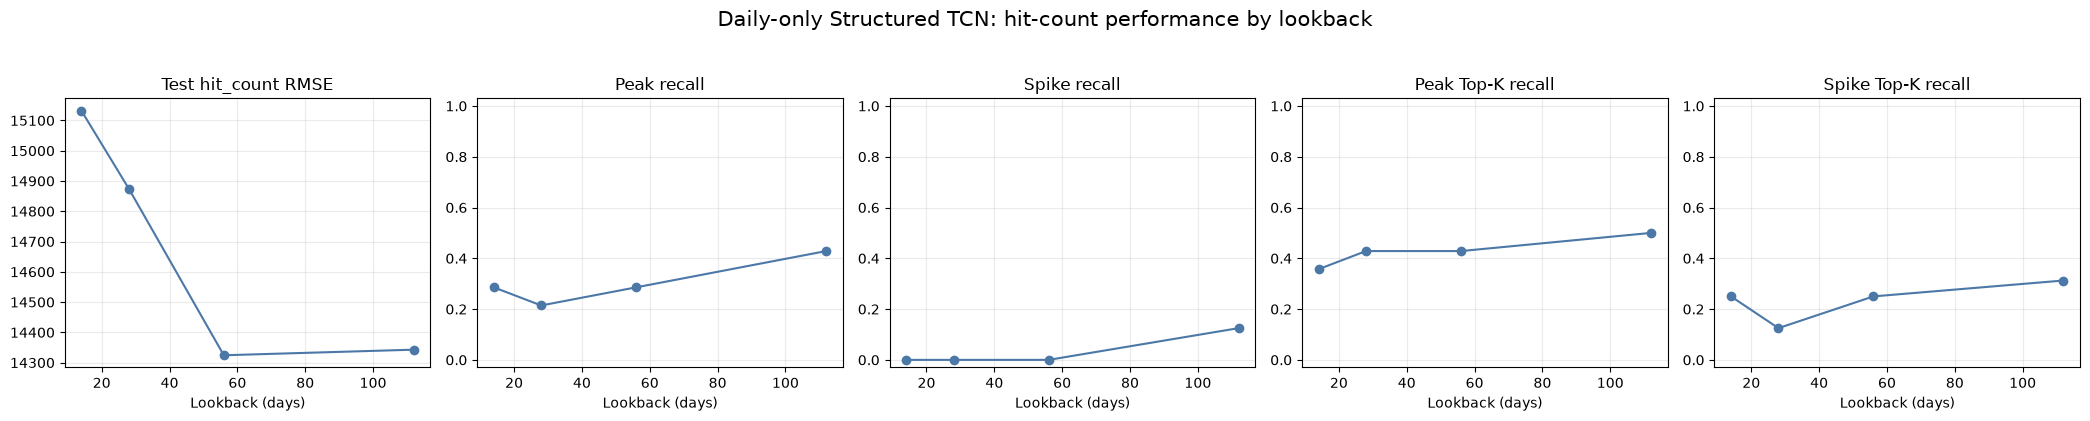

In [3]:
# This cell also works after a kernel restart: load required packages and the completed scan from disk.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

week8_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261028.ipynb').exists() else Path.cwd() / 'week8'
output_dir = week8_dir / 'results' / 'hit_count_long_lookback'
if 'lookback_results' not in globals():
    lookback_results = pd.read_csv(output_dir / 'daily_only_long_lookback_results.csv')

# The results table is ranked by validation RMSE; sort numerically before drawing a lookback curve.
plot_results = lookback_results.sort_values('lookback')
metric_labels = [('test_hit_count_rmse', 'Test hit_count RMSE'), ('peak_recall', 'Peak recall'), ('spike_recall', 'Spike recall'), ('peak_top_k_recall', 'Peak Top-K recall'), ('spike_top_k_recall', 'Spike Top-K recall')]
fig, axes = plt.subplots(1, len(metric_labels), figsize=(21, 4))
for axis, (metric, title) in zip(axes, metric_labels):
    axis.plot(plot_results['lookback'], plot_results[metric], marker='o', color='#4c78a8')
    axis.set_title(title)
    axis.set_xlabel('Lookback (days)')
    axis.grid(alpha=.25)
    if 'recall' in metric: axis.set_ylim(-.03, 1.03)
fig.suptitle('Daily-only Structured TCN: hit-count performance by lookback', y=1.04, fontsize=15)
fig.tight_layout()
fig.savefig(output_dir / 'daily_only_long_lookback_hit_count_metrics.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Phase 2: Do all-variable intraday summary features add value?

This cell uses the validation-selected daily lookback from Phase 1. The base and intraday-summary models use identical architecture, split, target, and seed; only their input channels differ.

In [16]:
candle_rows, candle_predictions = [], {}
for use_candles, label in [(False, 'Daily-only base'), (True, 'Daily + all-variable intraday summaries')]:
    print(f'Running: {label}, lookback = {best_daily_lookback} days')
    result, prediction = fit_and_evaluate(lookback=best_daily_lookback, use_candles=use_candles)
    result['model'] = label
    candle_rows.append(result)
    candle_predictions[label] = prediction

candle_results = pd.DataFrame(candle_rows)
candle_results.to_csv(output_dir / 'daily_vs_candlestick_results.csv', index=False)
for label, prediction in candle_predictions.items():
    safe_label = label.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')
    prediction.to_csv(output_dir / f'{safe_label}_predictions.csv', index=False)

display(candle_results[['model', 'input_channels', 'best_epoch', 'validation_hit_count_rmse', 'test_hit_count_rmse', 'peak_precision', 'peak_recall', 'peak_top_k_recall', 'spike_precision', 'spike_recall', 'spike_top_k_recall', 'peak_bias', 'spike_bias']].round(3))

Running: Daily-only base, lookback = 28 days
Running: Daily + all-variable intraday summaries, lookback = 28 days


,model,input_channels,best_epoch,validation_hit_count_rmse,test_hit_count_rmse,peak_precision,peak_recall,peak_top_k_recall,spike_precision,spike_recall,spike_top_k_recall,peak_bias,spike_bias
0,Daily-only base,6,3,7955.885,14874.570,0.6,0.214,0.429,0.000,0.00,0.125,-29136.922,-28176.142
1,Daily + all-variable intraday summaries,30,8,7425.230,15555.762,0.5,0.429,0.429,0.571,0.25,0.375,-21446.248,-18876.739


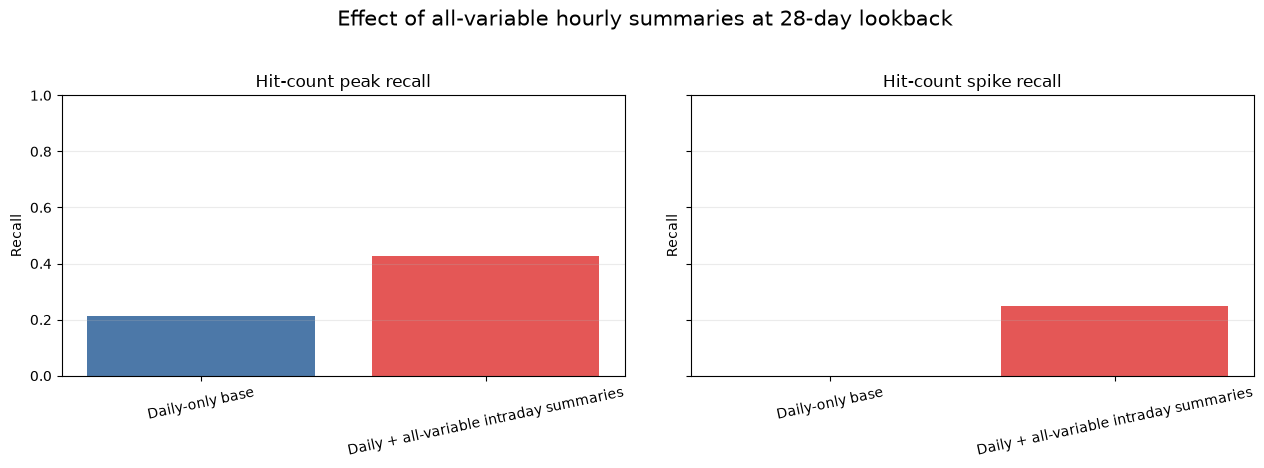

model,Daily-only base,Daily + all-variable intraday summaries,Candlestick improvement (%)
variable,,,
access_count,15674.631,16538.044,-5.508
access_size,41.650,40.227,3.415
hit_count,14874.570,15555.762,-4.580
hit_size,41.322,39.713,3.893
miss_count,1390.581,1429.061,-2.767
miss_size,1.831,2.063,-12.725


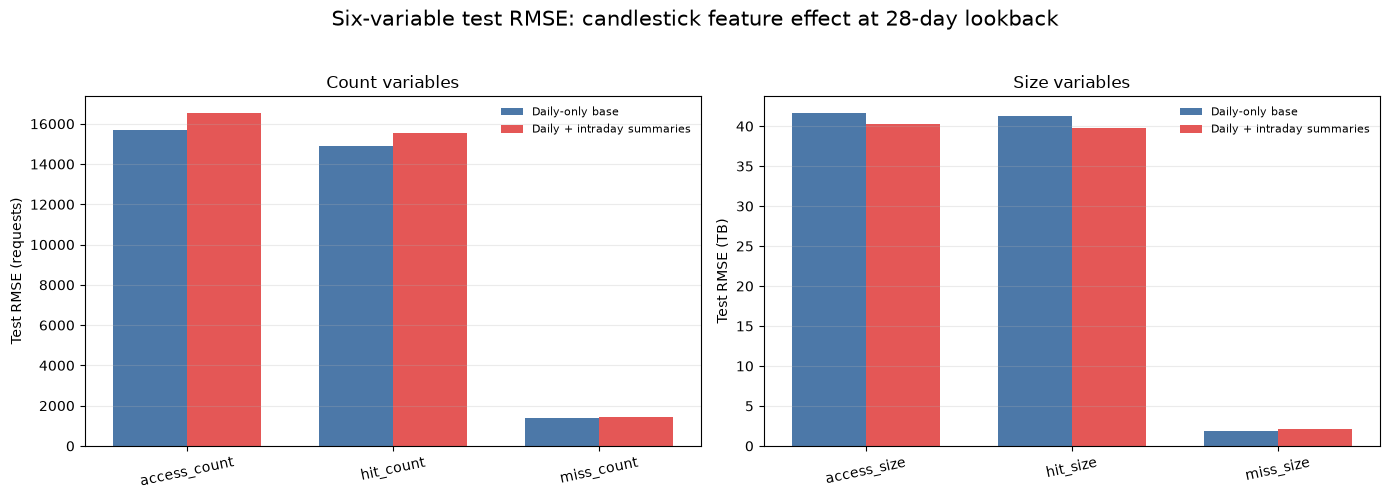

Results saved to: /Users/dengyingxin/Desktop/xcache/week8/results/hit_count_long_lookback


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axis, metric, title in zip(axes, ['peak_recall', 'spike_recall'], ['Hit-count peak recall', 'Hit-count spike recall']):
    axis.bar(candle_results['model'], candle_results[metric], color=['#4c78a8', '#e45756'])
    axis.set_title(title)
    axis.set_ylabel('Recall')
    axis.set_ylim(0, 1)
    axis.tick_params(axis='x', rotation=12)
    axis.grid(axis='y', alpha=.25)
fig.suptitle(f'Effect of all-variable hourly summaries at {best_daily_lookback}-day lookback', y=1.03, fontsize=15)
fig.tight_layout()
fig.savefig(output_dir / 'daily_vs_candlestick_event_recall.png', dpi=200, bbox_inches='tight')
plt.show()

# Compare the candlestick effect on every predicted XCache variable.
rmse_columns = [f'test_{variable}_rmse' for variable in FEATURE_NAMES]
six_variable_rmse = candle_results.set_index('model')[rmse_columns].T
six_variable_rmse.index = FEATURE_NAMES
six_variable_rmse.index.name = 'variable'
base_rmse = six_variable_rmse.iloc[:, 0]
candle_rmse = six_variable_rmse.iloc[:, 1]
six_variable_rmse['Candlestick improvement (%)'] = 100 * (base_rmse - candle_rmse) / base_rmse
six_variable_rmse.to_csv(output_dir / 'daily_vs_candlestick_six_variable_rmse.csv')
display(six_variable_rmse.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for axis, variable_group, unit, title in zip(
    axes,
    [['access_count', 'hit_count', 'miss_count'], ['access_size', 'hit_size', 'miss_size']],
    ['requests', 'TB'],
    ['Count variables', 'Size variables'],
):
    x = np.arange(len(variable_group))
    width = .36
    axis.bar(x - width / 2, base_rmse[variable_group], width, label='Daily-only base', color='#4c78a8')
    axis.bar(x + width / 2, candle_rmse[variable_group], width, label='Daily + intraday summaries', color='#e45756')
    axis.set_xticks(x, variable_group, rotation=12)
    axis.set_ylabel(f'Test RMSE ({unit})')
    axis.set_title(title)
    axis.grid(axis='y', alpha=.25)
    axis.legend(frameon=False, fontsize=8)
fig.suptitle(f'Six-variable test RMSE: candlestick feature effect at {best_daily_lookback}-day lookback', y=1.03, fontsize=15)
fig.tight_layout()
fig.savefig(output_dir / 'daily_vs_candlestick_six_variable_rmse.png', dpi=200, bbox_inches='tight')
plt.show()
print('Results saved to:', output_dir.resolve())